In [3]:
import pandas as pd
import sklearn

# Reload the original file, including all 303 records
from pathlib import Path

# Supports running from the repository root, models/, or beside heart.csv.
data_candidates = [
    Path("data/heart.csv"),
    Path("../data/heart.csv"),
    Path("heart.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "heart.csv was not found. Place the project dataset in the repository's "
        "data/ folder and run this notebook from the repository root or models/. "
        "Alternatively, place heart.csv beside the notebook."
    )
paper_df = pd.read_csv(data_path, encoding="utf-8-sig")

# Inspect the original data without modifying it
print("\nDataset shape:", paper_df.shape)
print("Missing entries:", paper_df.isna().sum().sum())
print("Extra duplicate rows:", paper_df.duplicated().sum())

print("\nTarget counts:")
print(paper_df["target"].value_counts().sort_index())

display(paper_df.head())


Dataset shape: (303, 14)
Missing entries: 0
Extra duplicate rows: 1

Target counts:
target
0    138
1    165
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 2. Preprocessing and Split: Original-Code Reproduction

The authors' ML implementation:
1. Separates the features from the target.
2. Applies Min–Max scaling to all features.
3. Uses an 80/20 split with random_state = 2.
4. Does not stratify the ML split.

We follow these choices here to reproduce the published code.

### Methodological limitations

The scaler is fitted before splitting, allowing test-set feature
ranges to influence preprocessing. This is data leakage.

The paper describes stratified sampling, but the published code
does not stratify the ML split. Its rule-classifier evaluation uses
a separate stratified split.

These choices are retained only for the original-code reproduction,
not presented as recommended practice.

Because we have already explored this dataset in our earlier
experiment, this is a retrospective reproduction rather than a
new untouched-test evaluation.

In [4]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Separate the 13 features from the target
paper_X = paper_df.drop(columns="target")
paper_y = paper_df["target"]

# Reproduce the authors' scaling order
# WARNING: fitting before splitting introduces data leakage
paper_scaler = MinMaxScaler()
paper_X_scaled = paper_scaler.fit_transform(paper_X)

# Reproduce the authors' ML split: no stratification
paper_X_train, paper_X_test, paper_y_train, paper_y_test = (
    train_test_split(
        paper_X_scaled,
        paper_y,
        test_size=0.20,
        random_state=2
    )
)

print("Training features:", paper_X_train.shape)
print("Test features:", paper_X_test.shape)

print("\nTraining target counts:")
print(paper_y_train.value_counts().sort_index())

print("\nTest target counts:")
print(paper_y_test.value_counts().sort_index())

Training features: (242, 13)
Test features: (61, 13)

Training target counts:
target
0    106
1    136
Name: count, dtype: int64

Test target counts:
target
0    32
1    29
Name: count, dtype: int64


## 3. Reproduce the Six Machine-Learning Models

The following classifiers use the settings in the authors' notebook:

| Model | Explicit settings |
|---|---|
| Logistic Regression | max_iter = 1000 |
| KNN | Default settings: 5 neighbors, uniform voting |
| SVM | gamma = "auto"; default RBF kernel and C = 1 |
| Gaussian Naive Bayes | Default settings |
| Decision Tree | random_state = 2 |
| Random Forest | 100 trees, random_state = 2 |

All six models use the same scaled training data and the same
61-record test set.

Accuracy, precision, recall, and F1 are calculated. Code 1 is
treated as the positive class without assigning a clinical meaning.

These results reproduce the original implementation, including
its preprocessing limitations. No hyperparameter tuning is performed.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the settings from the authors' notebook
paper_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(gamma="auto"),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=2),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=2
    )
}

paper_ml_rows = []
paper_ml_predictions = {}

# Train and evaluate each model on the same split
for name, model in paper_models.items():
    model.fit(paper_X_train, paper_y_train)
    predictions = model.predict(paper_X_test)

    # Preserve predictions for later confusion matrices
    paper_ml_predictions[name] = predictions

    paper_ml_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(paper_y_test, predictions),
        "Precision": precision_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        )
    })

# Keep full-precision results; round only the display
paper_ml_results = pd.DataFrame(paper_ml_rows)

display(
    paper_ml_results.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)

Model,Accuracy,Precision,Recall,F1
Logistic Regression,0.869,0.800,0.966,0.875
KNN,0.869,0.800,0.966,0.875
SVM,0.869,0.800,0.966,0.875
Naive Bayes,0.885,0.867,0.897,0.881
Decision Tree,0.869,0.800,0.966,0.875
Random Forest,0.902,0.829,1.000,0.906


### Machine-Learning Reproduction Results

All six classifiers matched the paper's reported accuracy,
precision, recall, and F1 at three decimal places.

Random Forest achieved the highest accuracy (0.902) and F1 (0.906).
Its recall of 1.000 indicates that all 29 class-1 test records
were correctly classified.

Logistic Regression, KNN, SVM, and Decision Tree produced identical
aggregate scores. Equal scores alone do not prove that their
individual predictions or decision boundaries are identical.

This agreement reproduces the authors' numerical results, including
the original implementation's preprocessing limitations.

## 4. Published GPT-4o Rule Classifier

This classifier implements the paper's fixed IF–THEN rules.

Rules are evaluated in order. The first matching condition returns
a class label, and the remaining conditions are skipped.

The rules use original, unscaled feature values because thresholds
such as age < 56 and thalach > 150 refer to those original values.

No model fitting, threshold tuning, or new LLM generation is involved.
Predictions remain class codes 0 and 1.

In [6]:
def paper_gpt4o_rules(row):
    """Implement the published GPT-4o rules in their original order."""

    if (
        row["cp"] > 0
        and row["thal"] <= 2
        and row["thalach"] > 150
    ):
        return 1

    elif row["cp"] > 0 and row["thal"] <= 2:
        return 1

    elif row["cp"] == 0 and row["ca"] > 0:
        return 0

    elif row["cp"] == 0 and row["thal"] > 2:
        return 0

    elif row["cp"] == 0 and row["exang"] == 1:
        return 0

    elif row["oldpeak"] > 2:
        return 0

    elif row["age"] < 56 and row["cp"] > 0:
        return 1

    else:
        return 0


print("Published GPT-4o rule classifier defined.")

Published GPT-4o rule classifier defined.


## 5. Published Claude Sonnet 4.6 Rule Classifier

This function reproduces the paper's fixed Sonnet rule set.

Each record is checked against the conditions in their original
order. The first matching rule returns class 0 or class 1.

The classifier uses original, unscaled feature values.
It requires no training and makes no calls to an LLM.

Thresholds and rule order are preserved for reproduction.
The predictions are class codes, not verified clinical diagnoses.

In [7]:
def paper_sonnet_rules(row):
    """Implement the published Sonnet rules in their original order."""

    if (
        row["cp"] > 0
        and row["thal"] == 2
        and row["oldpeak"] <= 3.5
    ):
        return 1

    elif (
        row["cp"] > 0
        and row["thal"] == 3
        and row["thalach"] > 150
        and row["oldpeak"] <= 2.2
    ):
        return 1

    elif (
        row["cp"] == 0
        and row["oldpeak"] <= 0.7
        and row["ca"] == 0
        and row["age"] > 41
    ):
        return 1

    elif (
        row["cp"] == 0
        and row["ca"] > 0
        and row["sex"] == 0
    ):
        return 1

    elif (
        row["cp"] == 0
        and row["oldpeak"] > 0.7
        and row["trestbps"] > 106
    ):
        return 0

    elif (
        row["cp"] > 0
        and row["thal"] == 3
        and row["thalach"] <= 150
    ):
        return 0

    elif (
        row["cp"] == 0
        and row["ca"] > 0
        and row["sex"] == 1
    ):
        return 0

    elif row["oldpeak"] > 3.5:
        return 0

    elif row["cp"] > 0:
        return 1

    else:
        return 0


print("Published Sonnet rule classifier defined.")

Published Sonnet rule classifier defined.


## 6. Evaluate the Published Rule Classifiers

The authors' code evaluates the rule classifiers using a stratified
80/20 split with random_state = 2.

This differs from the non-stratified split used for the six ML
models. We preserve this difference to reproduce Table I, but it
means the original comparison uses different test records.

Both rule classifiers receive original, unscaled feature values.
Their thresholds and rule order remain fixed.

Precision, recall, and F1 treat target code 1 as the positive class.

In [8]:
# Reproduce the authors' separate split for rule evaluation
_, paper_rules_X_test, _, paper_rules_y_test = train_test_split(
    paper_X,
    paper_y,
    test_size=0.20,
    random_state=2,
    stratify=paper_y
)

print("Rule test-set target counts:")
print(paper_rules_y_test.value_counts().sort_index())

# Store the two previously defined rule functions
paper_rule_models = {
    "GPT-4o Rules": paper_gpt4o_rules,
    "Sonnet 4.6 Rules": paper_sonnet_rules
}

paper_rule_rows = []
paper_rule_predictions = {}

# Apply each fixed classifier to the unscaled test records
for name, rule_function in paper_rule_models.items():
    predictions = paper_rules_X_test.apply(
        rule_function,
        axis=1
    )

    paper_rule_predictions[name] = predictions

    paper_rule_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(
            paper_rules_y_test, predictions
        ),
        "Precision": precision_score(
            paper_rules_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            paper_rules_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            paper_rules_y_test, predictions,
            pos_label=1, zero_division=0
        )
    })

paper_rule_results = pd.DataFrame(paper_rule_rows)

display(
    paper_rule_results.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)

Rule test-set target counts:
target
0    28
1    33
Name: count, dtype: int64


Model,Accuracy,Precision,Recall,F1
GPT-4o Rules,0.705,0.800,0.606,0.690
Sonnet 4.6 Rules,0.803,0.769,0.909,0.833


### Rule Classifier Results

| Classifier | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| GPT-4o Rules | 0.705 | 0.800 | 0.606 | 0.690 |
| Sonnet 4.6 Rules | 0.803 | 0.769 | 0.909 | 0.833 |

Both fixed rule classifiers match Table I at three decimal places.

Sonnet achieved higher accuracy, recall, and F1 than GPT-4o.
GPT-4o achieved slightly higher precision.

Sonnet identified 30 of the 33 class-1 records, while GPT-4o
identified 20.

Together with the six ML classifiers, all eight reported results
have been reproduced at the paper's displayed precision.

However, the original ML and rule evaluations use different test
records. Matching the published scores does not resolve that
comparability limitation.

## 7. Comparison with the Paper's Table I

The following table combines all eight reproduced results.

Each metric is compared with the corresponding published value
after rounding to three decimal places.

A match means agreement at the paper's reporting precision,
not equality of unrounded scores.

The original implementation uses:
- A non-stratified test split for ML classifiers.
- A separate stratified test split for rule classifiers.

This table reproduces those procedures; it is not a corrected
same-test-set comparison.

In [9]:
import numpy as np

# Combine the actual results without changing their precision
paper_all_results = pd.concat(
    [paper_ml_results, paper_rule_results],
    ignore_index=True
)

# Values reported in the paper's Table I
paper_reference = pd.DataFrame([
    ["Random Forest",       0.902, 0.829, 1.000, 0.906],
    ["Naive Bayes",         0.885, 0.867, 0.897, 0.881],
    ["KNN",                0.869, 0.800, 0.966, 0.875],
    ["Logistic Regression", 0.869, 0.800, 0.966, 0.875],
    ["SVM",                0.869, 0.800, 0.966, 0.875],
    ["Decision Tree",      0.869, 0.800, 0.966, 0.875],
    ["Sonnet 4.6 Rules",    0.803, 0.769, 0.909, 0.833],
    ["GPT-4o Rules",        0.705, 0.800, 0.606, 0.690]
], columns=["Model", "Accuracy", "Precision", "Recall", "F1"])

metrics = ["Accuracy", "Precision", "Recall", "F1"]

# Align results by model name in the paper's order
actual = (
    paper_all_results
    .set_index("Model")
    .loc[paper_reference["Model"], metrics]
)

expected = paper_reference.set_index("Model")[metrics]

# Check all four metrics for each model at three-decimal precision
matches = np.isclose(
    actual.round(3).to_numpy(),
    expected.to_numpy(),
    rtol=0,
    atol=1e-12
).all(axis=1)

reproduction_table = actual.copy()
reproduction_table["Matches paper (3 d.p.)"] = matches

display(
    reproduction_table.style.format({
        metric: "{:.3f}" for metric in metrics
    })
)

print(f"Models matching all four metrics: {matches.sum()} / 8")

,Accuracy,Precision,Recall,F1,Matches paper (3 d.p.)
Model,,,,,
Random Forest,0.902,0.829,1.000,0.906,True
Naive Bayes,0.885,0.867,0.897,0.881,True
KNN,0.869,0.800,0.966,0.875,True
Logistic Regression,0.869,0.800,0.966,0.875,True
SVM,0.869,0.800,0.966,0.875,True
Decision Tree,0.869,0.800,0.966,0.875,True
Sonnet 4.6 Rules,0.803,0.769,0.909,0.833,True
GPT-4o Rules,0.705,0.800,0.606,0.690,True


Models matching all four metrics: 8 / 8


### Reproduction Conclusion

All eight models matched the accuracy, precision, recall, and
F1-score reported in Table I at three decimal places.

Random Forest obtained the highest reported accuracy (90.2%)
and F1-score (0.906). Sonnet's fixed rules performed better than
GPT-4o's rules on accuracy, recall, and F1.

This confirms numerical reproduction of the published implementation
at its reporting precision, rather than independent validation of
the study's conclusions.

Two methodological limitations remain:
- Min–Max scaling was fitted before the train–test split.
- ML classifiers and rule classifiers were evaluated on different
  test records.

Therefore, the reported ML-versus-rules performance gap should
not be interpreted as a controlled same-test-set comparison.

Target labels remain described as class codes until their clinical
mapping is independently verified.

## 8. Same-Test-Set Comparison

The original implementation evaluated ML models and rule classifiers
on different test records.

Here, both fixed rule classifiers are evaluated on the same 61
records used for the ML models. Their rules remain unchanged.

We retrieve these records in their original, unscaled form because
the rule thresholds require original feature values.

The ML results remain unchanged. This comparison addresses only
the test-record mismatch; it does not correct preprocessing leakage.

This is a retrospective diagnostic analysis, not a fresh independent
test or a reason to tune the rules.

In [10]:
# Retrieve the original, unscaled records in ML test-set order
same_test_X = paper_X.loc[paper_y_test.index]

# Verify that records and labels are aligned
assert same_test_X.index.equals(paper_y_test.index)

same_test_rule_rows = []

# Evaluate the unchanged rules on the ML test records
for name, rule_function in paper_rule_models.items():
    predictions = same_test_X.apply(rule_function, axis=1)

    same_test_rule_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(paper_y_test, predictions),
        "Precision": precision_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            paper_y_test, predictions,
            pos_label=1, zero_division=0
        )
    })

same_test_rule_results = pd.DataFrame(same_test_rule_rows)

# Compare original rule results with same-test-set results
rule_split_comparison = paper_rule_results.merge(
    same_test_rule_results,
    on="Model",
    suffixes=("_original", "_same_test"),
    validate="one_to_one"
)

display(
    rule_split_comparison.style
    .hide(axis="index")
    .format({
        column: "{:.3f}"
        for column in rule_split_comparison.columns
        if column != "Model"
    })
)

Model,Accuracy_original,Precision_original,Recall_original,F1_original,Accuracy_same_test,Precision_same_test,Recall_same_test,F1_same_test
GPT-4o Rules,0.705,0.800,0.606,0.690,0.852,0.885,0.793,0.836
Sonnet 4.6 Rules,0.803,0.769,0.909,0.833,0.836,0.788,0.897,0.839


### Finding: Test-Set Choice Changes the Comparison

The unchanged rule classifiers were evaluated on the same 61
records used for the ML models.

| Classifier | Original accuracy | Same-test accuracy | Original F1 | Same-test F1 |
|---|---:|---:|---:|---:|
| GPT-4o rules | 70.5% | 85.2% | 0.690 | 0.836 |
| Sonnet rules | 80.3% | 83.6% | 0.833 | 0.839 |

GPT-4o's accuracy increased by approximately 14.7 percentage
points, while Sonnet's increased by approximately 3.3 points.
These changes resulted from evaluating different records,
not from improving the classifiers.

Random Forest's accuracy remains 90.2%. Its accuracy gap over
GPT-4o therefore decreases from approximately 19.7 to 5.0
percentage points, and its gap over Sonnet decreases from
approximately 9.9 to 6.6 points.

On the shared test records, GPT-4o has higher accuracy than
Sonnet, while Sonnet has slightly higher F1.

### Interpretation

The original performance gap was sensitive to which records
were used for evaluation. Testing all classifiers on identical
records provides a more comparable assessment.

The six ML models still have higher accuracy and F1 than the
two rule classifiers on this shared split, but the differences
are smaller than in the original comparison.

### Remaining Limitations

This analysis corrects only the test-record mismatch.
The ML preprocessing still includes scaling fitted before splitting.

The test set is small, and this retrospective comparison does
not establish statistically reliable superiority or performance
on new patient populations.

The published rules remain fixed. Their original generation
history has not been independently verified.

## 9. Corrected Evaluation: Training-Only Scaling and a Shared Split

This experiment makes two changes to the original implementation:
1. All classifiers use the same stratified 80/20 split.
2. Each ML model's scaler is fitted only on training records.

The original 303 records, model settings, and fixed rules are retained.
ML models receive scaled features; rules receive original values.

These results are reported separately from the paper reproduction.
Because both splitting and scaling change, differences cannot be
attributed to either change alone.

This remains a retrospective experiment on an already-explored
dataset, not an independent external validation.

In [11]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Split original, unscaled data once for all classifiers
corrected_X_train, corrected_X_test, corrected_y_train, corrected_y_test = (
    train_test_split(
        paper_X,
        paper_y,
        test_size=0.20,
        random_state=2,
        stratify=paper_y
    )
)

corrected_rows = []
corrected_models = {}

# Fit each ML model with training-only scaling
for name, model in paper_models.items():
    pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", clone(model))
    ])

    pipeline.fit(corrected_X_train, corrected_y_train)
    predictions = pipeline.predict(corrected_X_test)

    corrected_models[name] = pipeline

    corrected_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(corrected_y_test, predictions),
        "Precision": precision_score(
            corrected_y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            corrected_y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            corrected_y_test, predictions, zero_division=0
        )
    })

# Evaluate fixed rules on the same records, without scaling
for name, rule_function in paper_rule_models.items():
    predictions = corrected_X_test.apply(rule_function, axis=1)

    corrected_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(corrected_y_test, predictions),
        "Precision": precision_score(
            corrected_y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            corrected_y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            corrected_y_test, predictions, zero_division=0
        )
    })

corrected_results = pd.DataFrame(corrected_rows)

display(
    corrected_results.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)

Model,Accuracy,Precision,Recall,F1
Logistic Regression,0.803,0.800,0.848,0.824
KNN,0.787,0.794,0.818,0.806
SVM,0.803,0.800,0.848,0.824
Naive Bayes,0.820,0.893,0.758,0.820
Decision Tree,0.770,0.788,0.788,0.788
Random Forest,0.787,0.812,0.788,0.800
GPT-4o Rules,0.705,0.800,0.606,0.690
Sonnet 4.6 Rules,0.803,0.769,0.909,0.833


### Corrected Evaluation Results

All eight classifiers were evaluated on the same stratified
61-record test set. ML scaling was fitted on training records only.

| Model | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.803 | 0.800 | 0.848 | 0.824 |
| KNN | 0.787 | 0.794 | 0.818 | 0.806 |
| SVM | 0.803 | 0.800 | 0.848 | 0.824 |
| Naive Bayes | 0.820 | 0.893 | 0.758 | 0.820 |
| Decision Tree | 0.770 | 0.788 | 0.788 | 0.788 |
| Random Forest | 0.787 | 0.812 | 0.788 | 0.800 |
| GPT-4o Rules | 0.705 | 0.800 | 0.606 | 0.690 |
| Sonnet 4.6 Rules | 0.803 | 0.769 | 0.909 | 0.833 |

#### Main Findings

- Naive Bayes achieved the highest accuracy and precision.
- Sonnet achieved the highest recall and F1.
- Logistic Regression, SVM, and Sonnet had equal accuracy.
- Random Forest, which led the original results, no longer ranked first.
- Both rule classifiers retained their original scores because
  their test records and rules were unchanged.

#### Interpretation

On this corrected split, traditional ML models did not uniformly
outperform the LLM-generated rule classifiers: Sonnet's fixed rules
achieved the highest F1.

However, Naive Bayes correctly classified 50 of 61 records, compared
with 49 for Sonnet, Logistic Regression, and SVM. Its accuracy
advantage therefore represents only one additional correct prediction.

The split and scaling procedure changed together, so the observed
differences cannot be attributed to scaling leakage alone.

These results demonstrate sensitivity to the evaluation setup,
not definitive superiority of one model family.

#### Remaining Limitations

This is still a single small test split from an already-explored
dataset. The duplicate record and unresolved category codes remain.

The provenance of the published rules and their original training
records has not been independently verified. Consequently, we cannot
guarantee that this corrected test set was unseen during rule generation.

Recall and F1 refer to target code 1, whose clinical meaning still
requires independent verification.

## 10. Robustness Check: Ten-Fold Cross-Validation

A single train–test split can produce a ranking that depends on
which records happen to be selected.

We evaluate the six ML classifiers using ten-fold stratified
cross-validation. Each record is used for validation once, while
the remaining nine folds are used for training.

Min–Max scaling is fitted separately within each fold's training
portion. Model settings remain unchanged; no tuning is performed.

Mean accuracy and F1 summarize performance. Their standard deviations
describe variation across folds and are not confidence intervals.

This analysis uses all 303 records, including records from earlier
test splits. It is a retrospective robustness check, not another
independent held-out test.

The duplicate record is retained for consistency with the reproduction.
It may cross fold boundaries, which remains a limitation.

The published LLM rules are excluded because their original
rule-generation training records have not been independently verified.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use the same reproducible folds for all six ML models
robustness_cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

robustness_rows = []

for name, model in paper_models.items():
    # Fresh model; scaling is learned inside each training fold
    pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("model", clone(model))
    ])

    fold_scores = cross_validate(
        pipeline,
        paper_X,
        paper_y,
        cv=robustness_cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1"
        },
        n_jobs=-1
    )

    robustness_rows.append({
        "Model": name,
        "Mean accuracy": fold_scores["test_accuracy"].mean(),
        "Accuracy std": fold_scores["test_accuracy"].std(),
        "Mean F1": fold_scores["test_f1"].mean(),
        "F1 std": fold_scores["test_f1"].std()
    })

robustness_results = (
    pd.DataFrame(robustness_rows)
    .sort_values("Mean accuracy", ascending=False)
    .reset_index(drop=True)
)

display(
    robustness_results.style
    .hide(axis="index")
    .format({
        "Mean accuracy": "{:.3f}",
        "Accuracy std": "{:.3f}",
        "Mean F1": "{:.3f}",
        "F1 std": "{:.3f}"
    })
)

Model,Mean accuracy,Accuracy std,Mean F1,F1 std
KNN,0.838,0.061,0.852,0.054
Random Forest,0.835,0.051,0.851,0.049
Logistic Regression,0.825,0.050,0.848,0.043
SVM,0.821,0.068,0.848,0.054
Naive Bayes,0.808,0.068,0.827,0.057
Decision Tree,0.765,0.065,0.787,0.058


### Ten-Fold Cross-Validation Results

| Model | Mean accuracy | Accuracy std | Mean F1 | F1 std |
|---|---:|---:|---:|---:|
| KNN | 0.838 | 0.061 | 0.852 | 0.054 |
| Random Forest | 0.835 | 0.051 | 0.851 | 0.049 |
| Logistic Regression | 0.825 | 0.050 | 0.848 | 0.043 |
| SVM | 0.821 | 0.068 | 0.848 | 0.054 |
| Naive Bayes | 0.808 | 0.068 | 0.827 | 0.057 |
| Decision Tree | 0.765 | 0.065 | 0.787 | 0.058 |

#### Interpretation

KNN achieved the highest mean accuracy and F1, followed closely
by Random Forest.

The accuracy difference between them was approximately 0.3
percentage points, and the F1 difference was 0.001. These small
differences do not establish statistically reliable superiority.

Logistic Regression and SVM also performed similarly to the
leading models. Decision Tree had the lowest mean accuracy and F1.

Accuracy standard deviations ranged from 5.0 to 6.8 percentage
points, indicating variation across validation folds. These
standard deviations are not confidence intervals.

#### Comparison Across Evaluation Setups

The leading model changed with the evaluation setup:
- Original published split: Random Forest led accuracy.
- Corrected stratified split: Naive Bayes led accuracy.
- Ten-fold cross-validation: KNN had the highest mean accuracy,
  narrowly ahead of Random Forest.

This supports reporting performance across multiple folds rather
than relying on a single split to identify a best model.

#### Limitations

This is a retrospective analysis of the same 303 records, not
external validation. The duplicate record was retained and may
cross fold boundaries.

The published LLM rules were not included because their original
rule-generation training records could not be independently verified.

## 11. Accuracy Across Evaluation Setups

This chart compares the six ML classifiers under:
1. The original-code reproduction.
2. A shared stratified split with training-only scaling.
3. Ten-fold cross-validation with scaling inside each fold.

The first two results are single-split accuracies. The third is
mean cross-validation accuracy, so these are descriptive comparisons
rather than equivalent independent estimates.

The chart illustrates how the evaluation setup affects reported
performance and model rankings.

The original and corrected workflows change both splitting and
scaling. Their differences cannot be attributed to scaling alone.

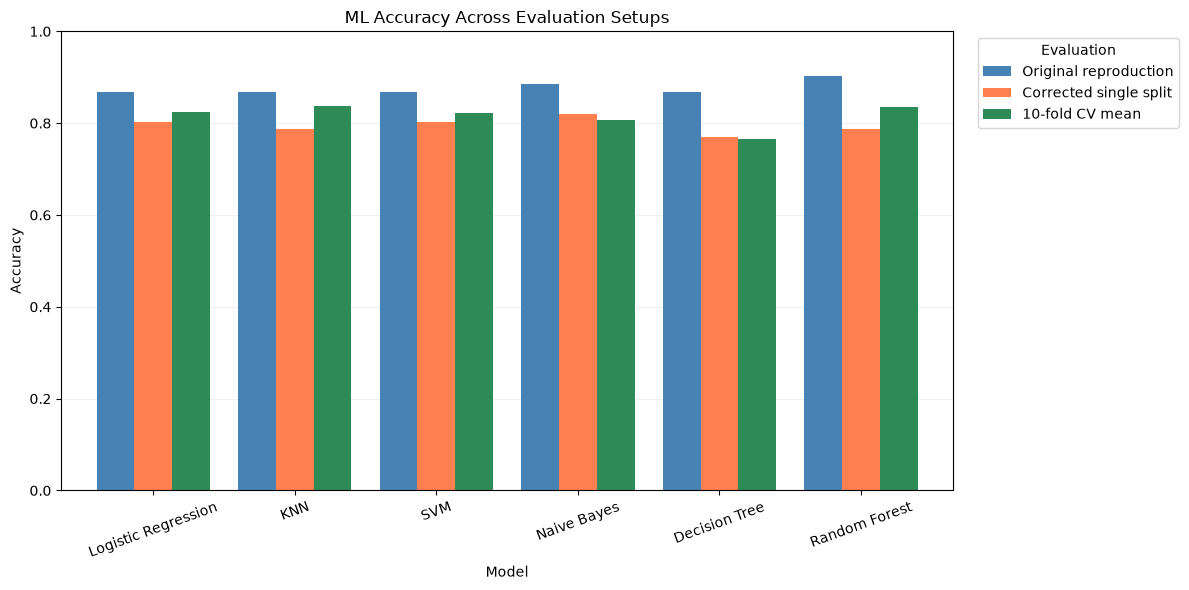

,Original reproduction,Corrected single split,10-fold CV mean
Model,,,
Logistic Regression,0.869,0.803,0.825
KNN,0.869,0.787,0.838
SVM,0.869,0.803,0.821
Naive Bayes,0.885,0.820,0.808
Decision Tree,0.869,0.770,0.765
Random Forest,0.902,0.787,0.835


In [14]:
import matplotlib.pyplot as plt

# Keep a consistent model order
model_order = list(paper_models.keys())

# Align existing results by model name
original_accuracy = (
    paper_ml_results.set_index("Model")["Accuracy"]
)

corrected_accuracy = (
    corrected_results.set_index("Model")["Accuracy"]
)

cv_accuracy = (
    robustness_results.set_index("Model")["Mean accuracy"]
)

# Build the comparison table using stored, unrounded results
accuracy_comparison = pd.DataFrame({
    "Original reproduction": original_accuracy.reindex(model_order),
    "Corrected single split": corrected_accuracy.reindex(model_order),
    "10-fold CV mean": cv_accuracy.reindex(model_order)
})

# Plot three bars for each ML model
ax = accuracy_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
    color=["steelblue", "coral", "seagreen"]
)

ax.set_title("ML Accuracy Across Evaluation Setups")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
# Place the legend outside the plotting area
ax.legend(
    title="Evaluation",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Display exact values to three decimal places
display(accuracy_comparison.style.format("{:.3f}"))

### Interpretation: Accuracy Across Evaluation Setups

All six ML models achieved higher accuracy in the original
reproduction than in either subsequent evaluation.

The leading model changed:
- Original reproduction: Random Forest, 90.2%.
- Corrected single split: Naive Bayes, 82.0%.
- Ten-fold cross-validation: KNN, 83.8%, closely followed by
  Random Forest at 83.5%.

Random Forest's accuracy decreased from 90.2% in the original
reproduction to 78.7% on the corrected split. Its cross-validation
mean was 83.5%, illustrating how a single split can differ from
performance averaged across folds.

These results show that model rankings and reported accuracy
depend on the evaluation setup.

The differences cannot be attributed solely to scaling leakage:
the original and corrected experiments also used different splits.
Cross-validation additionally changes training-set sizes and
averages results across multiple validation folds.

The chart provides a descriptive comparison, not a statistical
significance test or evidence that one model is universally best.

## 12. Conclusion

### Reproduction

We reproduced all eight models' accuracy, precision, recall,
and F1-score from Alaswad et al. (2026) at three decimal places.

This confirms numerical agreement with the published implementation
at its reporting precision.

### Evaluation Findings

The authors' implementation fitted scaling before splitting and
used different test records for ML and rule classifiers.

When the unchanged rules were evaluated on the ML test records:
- GPT-4o accuracy increased from 70.5% to 85.2%.
- Sonnet accuracy increased from 80.3% to 83.6%.

These changes reflect different evaluation records, not improvements
to the rules.

With training-only scaling and one shared stratified split:
- Naive Bayes achieved the highest accuracy, 82.0%.
- Sonnet achieved the highest F1, 0.833.

In ten-fold cross-validation of the six ML models:
- KNN achieved the highest mean accuracy, 83.8%.
- Random Forest followed closely at 83.5%.
- Their small difference does not establish a reliable winner.

### Overall Conclusion

Reproducing published scores and validating an evaluation method
are different tasks.

Our results show that the reported model rankings and ML-versus-rules
performance gap depend on the evaluation setup. Shared test records
and training-only preprocessing are essential for a fairer comparison.

The fixed rules are readable, but readability alone does not
establish clinical validity or usefulness.

## 13. Limitations and Future Work

### Limitations

- The dataset contains only 303 records.
- One duplicate was retained for reproduction and may cross
  training and validation boundaries.
- Target-label meanings and undocumented feature codes have
  not been independently verified in this notebook.
- The published rules' original generation data could not be
  independently verified.
- Later experiments are retrospective analyses of previously
  explored data, not fresh independent validations.
- The experiments did not isolate the effect of scaling from
  the effect of changing the split.
- No formal statistical comparison or clinical validation
  was performed.

### Future Work

- Verify target and feature encodings against the original
  dataset before assigning clinical interpretations.
- Prevent duplicate records from crossing evaluation boundaries.
- Compare scaling procedures while holding test records fixed.
- Use nested cross-validation if adding hyperparameter tuning.
- Evaluate generalization on an independent, appropriately
  harmonized dataset.
- Assess rule interpretability and clinical validity separately
  from predictive performance.

## References

Alaswad et al. (2026).
Evaluating LLM-Generated Rules for Heart Disease Prediction.
https://arxiv.org/abs/2609.13192

Authors' implementation and dataset:
https://github.com/FeisalAlaswad/LLM-Rule-ML-Heart-Disease-Prediction

Original UCI Heart Disease dataset documentation:
https://archive.ics.uci.edu/dataset/45/heart+disease